# Day 1 (v2) SOLUTIONS

One exercise at a time, then close this and retype from memory.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['axes.grid'] = True

## 0. Data (given)

Same synthetic book as before. The true model is

$$\text{logit}(p_i) = -5 + 3\,\text{dti}_i + 1.5\,\text{ltv}_i + 0.9\,\text{arrears}_i + 1.2\,\text{util}_i + 0\cdot\text{noise}_i$$

and each default is a Bernoulli draw: $y_i \sim \text{Bernoulli}(p_i)$. Because we *know* the truth, we can check every estimate against it.

In [7]:
df

,dti,ltv,months_in_arrears,utilisation,noise,true_pd,default
0,0.386566,0.711307,1,0.183514,0.450061,0.160687,1
1,0.225202,0.705077,1,0.240490,2.073894,0.111235,0
2,0.440054,0.645501,0,0.293653,-0.354710,0.086337,0
3,0.462868,0.814272,0,0.463544,1.023104,0.137794,0
4,0.115876,0.785197,0,0.215259,0.352892,0.038558,0
...,...,...,...,...,...,...,...
4995,0.479297,0.993016,1,0.158840,0.037468,0.272500,0
4996,0.308809,0.740523,0,0.312471,0.363073,0.069926,1
4997,0.443682,0.762787,0,0.318332,-0.108731,0.105008,0
4998,0.355969,0.918712,0,0.035676,2.615697,0.075076,0


In [8]:
Xmat

,const,dti,ltv,months_in_arrears,utilisation,noise
0,1.0,0.386566,0.711307,1,0.183514,0.450061
1,1.0,0.225202,0.705077,1,0.240490,2.073894
2,1.0,0.440054,0.645501,0,0.293653,-0.354710
3,1.0,0.462868,0.814272,0,0.463544,1.023104
4,1.0,0.115876,0.785197,0,0.215259,0.352892
...,...,...,...,...,...,...
4995,1.0,0.479297,0.993016,1,0.158840,0.037468
4996,1.0,0.308809,0.740523,0,0.312471,0.363073
4997,1.0,0.443682,0.762787,0,0.318332,-0.108731
4998,1.0,0.355969,0.918712,0,0.035676,2.615697


In [6]:
df[FEATURES]

,dti,ltv,months_in_arrears,utilisation,noise
0,0.386566,0.711307,1,0.183514,0.450061
1,0.225202,0.705077,1,0.240490,2.073894
2,0.440054,0.645501,0,0.293653,-0.354710
3,0.462868,0.814272,0,0.463544,1.023104
4,0.115876,0.785197,0,0.215259,0.352892
...,...,...,...,...,...
4995,0.479297,0.993016,1,0.158840,0.037468
4996,0.308809,0.740523,0,0.312471,0.363073
4997,0.443682,0.762787,0,0.318332,-0.108731
4998,0.355969,0.918712,0,0.035676,2.615697


In [2]:
TRUE_COEFS = {'const': -5.0, 'dti': 3.0, 'ltv': 1.5, 'months_in_arrears': 0.9, 'utilisation': 1.2, 'noise': 0.0}
FEATURES = ['dti', 'ltv', 'months_in_arrears', 'utilisation', 'noise']

def make_loans(n, seed):
    rng = np.random.default_rng(seed)
    df = pd.DataFrame({
        'dti': rng.normal(0.35, 0.12, n).clip(0, 1),
        'ltv': rng.normal(0.75, 0.15, n).clip(0.1, 1.2),
        'months_in_arrears': rng.poisson(0.3, n),
        'utilisation': rng.beta(2, 5, n),
        'noise': rng.normal(0, 1, n),
    })
    lin = TRUE_COEFS['const'] + sum(TRUE_COEFS[f] * df[f] for f in FEATURES)
    df['true_pd'] = 1 / (1 + np.exp(-lin))
    df['default'] = rng.binomial(1, df['true_pd'])
    return df

df = make_loans(5000, seed=42)
y = df['default'].values
Xmat = sm.add_constant(df[FEATURES])      # DataFrame: const + 5 features
print(f"{len(df)} loans, {y.sum()} defaults ({y.mean():.1%})")

5000 loans, 575 defaults (11.5%)


### Plotting helpers (given, just run)
You don't need to understand these line by line. They draw the pictures once your exercises produce the numbers.

In [3]:
def profile_loglik(var, grid, data=df, features=FEATURES):
    """Profile log-likelihood for one coefficient: fix beta_var at each grid value,
    re-optimise all the other coefficients, return the best log-likelihood."""
    others = [f for f in features if f != var]
    Xo = sm.add_constant(data[others])
    out = []
    for b in grid:
        fit = sm.GLM(data['default'], Xo, family=sm.families.Binomial(),
                     offset=b * data[var]).fit()
        out.append(fit.llf)
    return np.array(out)

def plot_chi2_tail(stat, title):
    xmax = max(10, stat * 1.3)
    x = np.linspace(0.01, xmax, 500)
    plt.plot(x, stats.chi2.pdf(x, 1), color='black', label=r'$\chi^2_1$ density')
    xs = x[x >= stat]
    plt.fill_between(xs, stats.chi2.pdf(xs, 1), color='red', alpha=0.4,
                     label=f'p = P($\\chi^2_1$ ≥ {stat:.2f}) = {stats.chi2.sf(stat, 1):.3f}')
    plt.axvline(stat, color='red', ls='--')
    plt.ylim(0, 1.2); plt.xlabel('test statistic'); plt.ylabel('density')
    plt.title(title); plt.legend(); plt.show()

---
## 1. The logistic model

**Theory.** A linear combination of features can be any number from $-\infty$ to $+\infty$. A PD must lie between 0 and 1. The logistic function squashes one into the other.

**Maths.** For loan $i$ with feature vector $x_i$ (including a 1 for the constant):

$$\eta_i = x_i^\top \beta \qquad \text{(linear predictor, or "score")}$$

$$p_i = \frac{1}{1 + e^{-\eta_i}} \qquad \Longleftrightarrow \qquad \log\frac{p_i}{1-p_i} = \eta_i$$

The left side of the second equation is the **log-odds**. So a coefficient $\beta_j$ means:

$$\text{a one-unit increase in } x_j \text{ adds } \beta_j \text{ to the log-odds} \quad\Longleftrightarrow\quad \text{multiplies the odds by } e^{\beta_j}$$

$e^{\beta_j}$ is the **odds ratio**.

**Picture.**

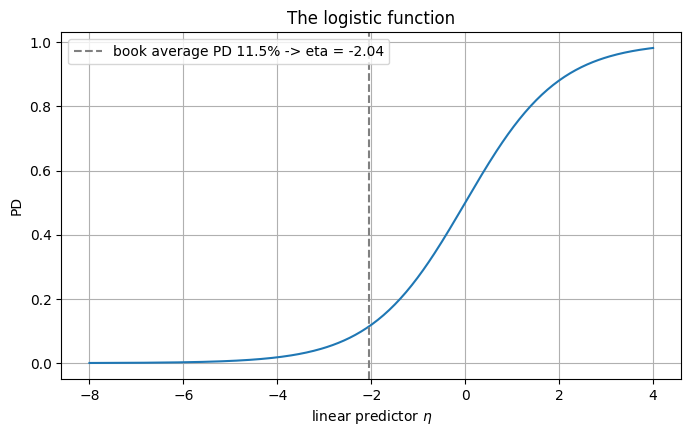

In [4]:
eta = np.linspace(-8, 4, 300)
plt.plot(eta, 1 / (1 + np.exp(-eta)))
avg_eta = np.log(y.mean() / (1 - y.mean()))
plt.axvline(avg_eta, color='grey', ls='--', label=f'book average PD {y.mean():.1%} -> eta = {avg_eta:.2f}')
plt.xlabel(r'linear predictor $\eta$'); plt.ylabel('PD'); plt.title('The logistic function'); plt.legend(); plt.show()

**Say out loud:** most of the book sits on the flat left-hand part of this curve. What does that mean for how much a +1 change in $\eta$ moves the PD for a typical loan, versus a loan with PD near 50%?

### Exercise 1.1: fit the model
Fit `sm.Logit(y, Xmat)` and store it as `full`.

In [5]:
full = sm.Logit(y, Xmat).fit(disp=0)
full.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                      y   No. Observations:                 5000
Model:                          Logit   Df Residuals:                     4994
Method:                           MLE   Df Model:                            5
Date:                Sat, 31 Oct 2026   Pseudo R-squ.:                 0.08068
Time:                        14:06:59   Log-Likelihood:                -1640.3
converged:                       True   LL-Null:                       -1784.2
Covariance Type:            nonrobust   LLR p-value:                 4.001e-60
=====================================================================================
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -5.1198      0.308    -16.650      0.000      -5.723      -4.517
dti                   2.8863      0.390      7.408      0.000       2.123       3.650
ltv                   1.7948      0.307      5.841      0.000       1.193       2.397
months_in_arrears     0.9885      0.068     14.479      0.000       0.855       1.122
utilisation           0.8374      0.277      3.024      0.002       0.295       1.380
noise                 0.0020      0.045      0.045      0.964      -0.087       0.091
=====================================================================================
"""

In [9]:
# CHECK
assert np.isclose(full.params['dti'], 2.8863, atol=1e-3)
print('1.1 passed')

1.1 passed


### Exercise 1.2: odds ratios
Compute `odds_ratios` = $e^{\hat\beta}$ for every parameter (a Series).

In [10]:
odds_ratios = np.exp(full.params)
odds_ratios.round(3)

const                 0.006
dti                  17.926
ltv                   6.018
months_in_arrears     2.687
utilisation           2.310
noise                 1.002
dtype: float64

In [ ]:
# CHECK
assert isinstance(odds_ratios, pd.Series)
assert 2.5 < odds_ratios['months_in_arrears'] < 2.9
print('1.2 passed')

**Say out loud:** "Each extra month in arrears multiplies the odds of default by ___." Then: why can't you say it multiplies the *probability* by that number? (Hint: what happens to a PD of 50% multiplied by 2.7?)

---
## 2. Likelihood and maximum likelihood estimation

**Theory.** The coefficients are chosen to make the defaults we actually observed as probable as possible. "Probable" is measured by the **likelihood**.

**Maths.** Each loan is Bernoulli, so the probability of its outcome is $p_i$ if it defaulted and $1-p_i$ if not. One formula covers both cases:

$$P(y_i) = p_i^{\,y_i}(1-p_i)^{1-y_i}$$

Loans are assumed independent, so the likelihood of the whole book is the product. Products of thousands of small numbers underflow, so we take logs:

$$\ell(\beta) = \sum_{i=1}^{n} \Big[\, y_i \log p_i + (1-y_i)\log(1-p_i) \,\Big], \qquad p_i = \frac{1}{1+e^{-x_i^\top\beta}}$$

The **MLE** $\hat\beta$ is the value of $\beta$ that maximises $\ell(\beta)$. That's what `.fit()` does.

### Exercise 2.1: write the log-likelihood yourself
Write `log_likelihood(beta, X, y)` using the formula above (numpy arrays in, a single number out). Then evaluate it at the fitted coefficients.

In [11]:
def log_likelihood(beta, X, y):
    p = 1 / (1 + np.exp(-X @ beta))
    return np.sum(y * np.log(p) + (1 - y) * np.log(1 - p))

ll_manual = log_likelihood(full.params.values, Xmat.values, y)
print(ll_manual, full.llf)

-1640.2666029162133 -1640.266602916213


In [12]:
# CHECK
assert np.isclose(ll_manual, full.llf)
beta_true = np.array([TRUE_COEFS[k] for k in Xmat.columns])
assert log_likelihood(beta_true, Xmat.values, y) < full.llf
print('2.1 passed. The MLE fits this sample better than even the TRUE coefficients do.')

2.1 passed. The MLE fits this sample better than even the TRUE coefficients do.


**Say out loud:** the second check passed. The *true* coefficients give a **lower** log-likelihood on this sample than the estimates do. How can the truth fit worse? (This is the essence of overfitting to sample noise.)

### Picture: the likelihood surface for one coefficient
Below is the **profile** log-likelihood for `utilisation`: for each candidate value of $\beta_{util}$, all other coefficients are re-optimised, and the best $\ell$ is plotted. The peak is the MLE. The dashed curve is a parabola with the *same curvature*; hold onto that for the next exercise.

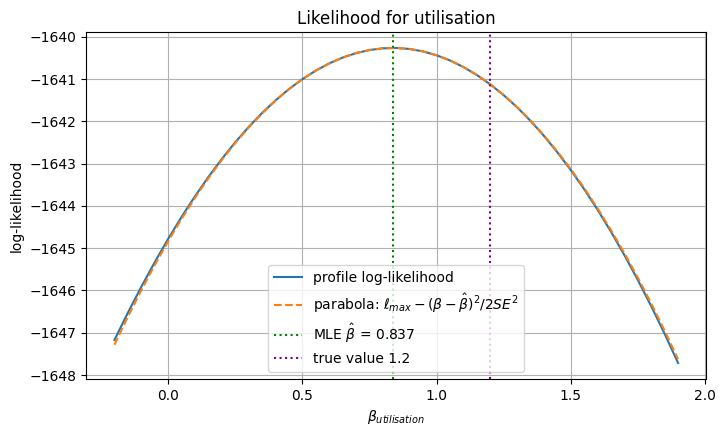

In [13]:
grid_u = np.linspace(-0.2, 1.9, 43)
prof_u = profile_loglik('utilisation', grid_u)
b_hat, se_u = full.params['utilisation'], full.bse['utilisation']

plt.plot(grid_u, prof_u, label='profile log-likelihood')
plt.plot(grid_u, full.llf - (grid_u - b_hat)**2 / (2 * se_u**2), ls='--', label=r'parabola: $\ell_{max} - (\beta-\hat\beta)^2 / 2SE^2$')
plt.axvline(b_hat, color='green', ls=':', label=rf'MLE $\hat\beta$ = {b_hat:.3f}')
plt.axvline(TRUE_COEFS['utilisation'], color='purple', ls=':', label='true value 1.2')
plt.xlabel(r'$\beta_{utilisation}$'); plt.ylabel('log-likelihood'); plt.legend(); plt.title('Likelihood for utilisation'); plt.show()

**The key idea:** a *sharp* peak means the data pins the coefficient down tightly, which gives a small standard error. A *flat* peak means many values fit almost equally well, which gives a large SE.

**Maths.** Curvature is measured by second derivatives. For logistic regression the matrix of (negative) second derivatives, the **Fisher information**, is

$$I(\hat\beta) = X^\top W X, \qquad W = \text{diag}\big(\hat p_i(1-\hat p_i)\big)$$

and the standard errors are

$$\text{Cov}(\hat\beta) \approx I(\hat\beta)^{-1}, \qquad SE(\hat\beta_j) = \sqrt{\big[I(\hat\beta)^{-1}\big]_{jj}}$$

### Exercise 2.2: standard errors from scratch
1. `p_hat`: fitted PDs (`full.predict(Xmat)` or compute them yourself)
2. `w` = $\hat p(1-\hat p)$
3. `info` = $X^\top W X$. *Tip: `Xv.T @ (Xv * w[:, None])` avoids a 5000×5000 matrix.*
4. `se_manual`: square roots of the diagonal of `np.linalg.inv(info)`, as a Series indexed like `full.params`

In [27]:
Xv = Xmat.values
p_hat = 1 / (1 + np.exp(-Xv @ full.params.values))
w = p_hat * (1 - p_hat)
info = Xv.T @ (Xv * w[:, None])
se_manual = pd.Series(np.sqrt(np.diag(np.linalg.inv(info))), index=full.params.index)
pd.DataFrame({'se_manual': se_manual, 'statsmodels': full.bse})

,se_manual,statsmodels
const,0.307504,0.307504
dti,0.389615,0.389615
ltv,0.307279,0.307279
months_in_arrears,0.068273,0.068273
utilisation,0.276907,0.276907
noise,0.045376,0.045376


In [15]:
# CHECK
assert np.allclose(se_manual, full.bse, rtol=1e-4)
print('2.2 passed. You just derived every std err in the summary table.')

2.2 passed. You just derived every std err in the summary table.


**Say out loud:** `w` = $\hat p(1-\hat p)$ is largest at $p = 0.5$ and tiny when $p$ is near 0. In a low-default book, most loans have $\hat p$ near 0. What does that do to the information, and so to the standard errors? Why do low-default portfolios have notoriously unstable models?

---
## 3. Sampling distributions: why ±1.96 SE works for 0/1 data

**Theory.** If we redrew the loan book many times, $\hat\beta$ would come out different each time. The spread of those estimates is the **sampling distribution**. The data is 0/1 and not normal, but the *estimate* is approximately normal in large samples.

**Maths.** For large $n$:

$$\hat\beta_j \;\overset{\text{approx}}{\sim}\; N\big(\beta_j,\; SE_j^2\big)$$

so

$$P\big(\hat\beta_j - 1.96\,SE_j \;\le\; \beta_j \;\le\; \hat\beta_j + 1.96\,SE_j\big) \approx 0.95$$

That's the 95% confidence interval. Note the randomness is in the **interval**, not in $\beta_j$: 95% of intervals built this way contain the truth.

### Exercise 3.1: see the sampling distribution
Loop 300 times. Each time: `make_loans(5000, seed=1000 + i)`, fit the full model, store:
- `est_dti`: the `dti` estimate
- `covers`: True/False, whether that fit's 95% CI for `dti` contains 3.0 (hint: `fit.conf_int()` returns a DataFrame with columns 0 and 1)

Make both numpy arrays. This takes ~15 seconds.

In [28]:
est_dti, covers = [], []
for i in range(300):
    d = make_loans(5000, seed=1000 + i)
    fit = sm.Logit(d['default'], sm.add_constant(d[FEATURES])).fit(disp=0)
    est_dti.append(fit.params['dti'])
    lo, hi = fit.conf_int().loc['dti']
    covers.append(lo <= 3.0 <= hi)
est_dti, covers = np.array(est_dti), np.array(covers)

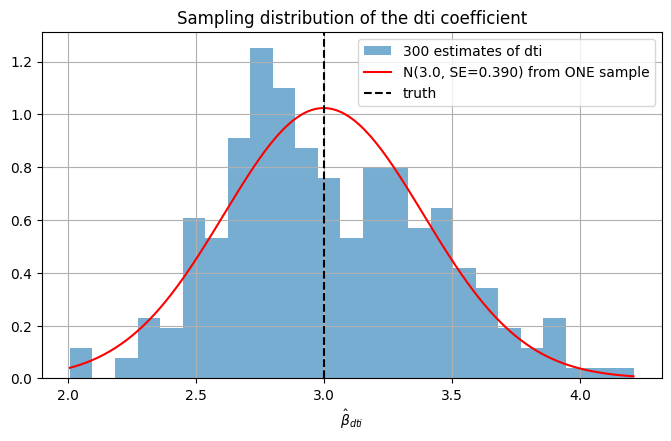

std of estimates: 0.404   SE from one fit: 0.390
CI coverage: 94.3%


In [29]:
# Picture (given)
xs = np.linspace(est_dti.min(), est_dti.max(), 200)
plt.hist(est_dti, bins=25, density=True, alpha=0.6, label='300 estimates of dti')
plt.plot(xs, stats.norm.pdf(xs, 3.0, full.bse['dti']), 'r', label=f'N(3.0, SE={full.bse["dti"]:.3f}) from ONE sample')
plt.axvline(3.0, color='black', ls='--', label='truth')
plt.xlabel(r'$\hat\beta_{dti}$'); plt.legend(); plt.title('Sampling distribution of the dti coefficient'); plt.show()
print(f'std of estimates: {est_dti.std():.3f}   SE from one fit: {full.bse["dti"]:.3f}')
print(f'CI coverage: {covers.mean():.1%}')

In [30]:
# CHECK
assert len(est_dti) == 300
assert abs(est_dti.std() / full.bse['dti'] - 1) < 0.2
assert 0.90 < covers.mean() < 0.99
print('3.1 passed')

3.1 passed


**Say out loud:**
1. The red curve came from a **single** dataset's standard error, yet it matches the spread across 300 datasets. Why is that remarkable, and what makes it work?
2. When would this break? (Think: number of *defaults*, not loans; and your separation experiment.)

---
## 4. The Wald test and the p-value

**Theory.** To test whether a variable matters, assume it doesn't ($H_0: \beta_j = 0$) and ask how surprising our estimate would be under that assumption.

**Maths.** Under $H_0$, using §3:

$$z_j = \frac{\hat\beta_j}{SE_j} \;\sim\; N(0,1) \qquad\Longrightarrow\qquad W_j = z_j^2 \;\sim\; \chi^2_1$$

(A $\chi^2_1$ variable is *defined* as the square of a standard normal.) The **p-value** is the probability, *assuming $H_0$ is true*, of a statistic at least this extreme:

$$p_j = P\big(\chi^2_1 \ge W_j\big) = P\big(|Z| \ge |z_j|\big) = 2\big(1 - \Phi(|z_j|)\big)$$

$$\boxed{\;p = P(\text{data this extreme} \mid H_0)\quad\neq\quad P(H_0 \mid \text{data})\;}$$

### Exercise 4.1: Wald statistics and p-values (keep the index!)
Compute `wald` and `p_wald` as **Series** indexed by parameter name.

In [19]:
wald = (full.params / full.bse) ** 2
p_wald = pd.Series(stats.chi2.sf(wald, df=1), index=wald.index)
pd.DataFrame({'z': full.params / full.bse, 'wald': wald, 'p_wald': p_wald}).round(4)

,z,wald,p_wald
const,-16.6496,277.2088,0.0000
dti,7.4080,54.8781,0.0000
ltv,5.8409,34.1160,0.0000
months_in_arrears,14.4793,209.6515,0.0000
utilisation,3.0243,9.1464,0.0025
noise,0.0447,0.0020,0.9644


In [20]:
# CHECK
assert isinstance(p_wald, pd.Series) and list(p_wald.index) == list(full.params.index)
assert np.allclose(p_wald, full.pvalues)
print('4.1 passed')

4.1 passed


### Exercise 4.2: the same p-value from the normal distribution
Compute `p_from_z` = $2(1-\Phi(|z|))$ using `stats.norm`. It must match `p_wald`. *Hint: `stats.norm.sf(x)` is $1 - \Phi(x)$.*

In [21]:
p_from_z = 2 * stats.norm.sf(np.abs(full.params / full.bse))

In [22]:
# CHECK
assert np.allclose(p_from_z, p_wald)
print('4.2 passed. Normal two-tailed test and chi-squared test are the same test.')

4.2 passed. Normal two-tailed test and chi-squared test are the same test.


### Picture: the p-value is a tail area
Red area = p-value. Compare a variable that matters with one that doesn't.

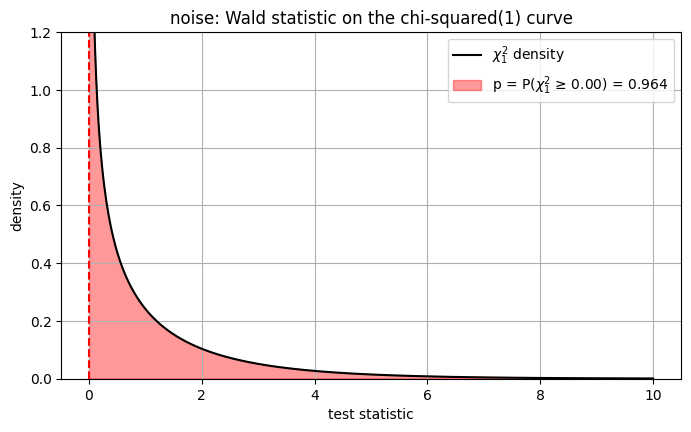

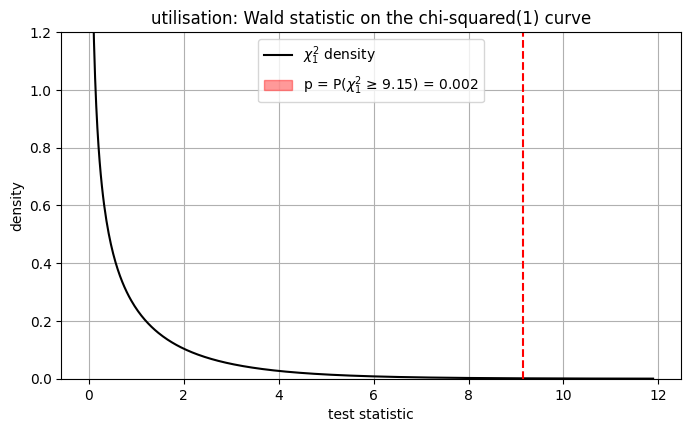

5% critical value: 3.841  (= 1.96 squared = 3.842)


In [23]:
plot_chi2_tail(wald['noise'], 'noise: Wald statistic on the chi-squared(1) curve')
plot_chi2_tail(wald['utilisation'], 'utilisation: Wald statistic on the chi-squared(1) curve')
print(f"5% critical value: {stats.chi2.ppf(0.95, 1):.3f}  (= 1.96 squared = {1.96**2:.3f})")

**Say out loud:**
1. Why is 3.841 the magic number for SAS's SLENTRY/SLSTAY = 0.05?
2. Explain the noise p-value of 0.964 in one sentence **without** saying "probability the variable is useless."
3. `ltv` has p ≈ 0.000 but its estimate is 1.79 vs a true 1.5. Does a tiny p-value mean the estimate is accurate? What *does* it tell you?

---
## 5. The likelihood-ratio test

**Theory.** Instead of asking how far $\hat\beta_j$ is from zero (Wald), ask how much **worse the fit gets** when we force $\beta_j = 0$.

**Maths.**

$$LR = 2\big(\ell_{\text{full}} - \ell_{\text{reduced}}\big) \;\sim\; \chi^2_{k} \quad \text{under } H_0$$

where $k$ = number of coefficients set to zero ($k=1$ for one variable). The factor of 2 makes it line up with $\chi^2$: for a perfect parabola (§2), $LR$ and $W$ are *identical*.

### Exercise 5.1
Write `lr_test(data, features, drop)` returning `(lr_stat, p_value)`: fit with and without `drop`, apply the formula.

In [24]:
def lr_test(data, features, drop):
    yy = data['default']
    f_full = sm.Logit(yy, sm.add_constant(data[features])).fit(disp=0)
    reduced = [f for f in features if f != drop]
    f_red = sm.Logit(yy, sm.add_constant(data[reduced])).fit(disp=0)
    lr = 2 * (f_full.llf - f_red.llf)
    return lr, stats.chi2.sf(lr, df=1)

for v in ['noise', 'utilisation', 'dti']:
    print(v, lr_test(df, FEATURES, v))

noise (np.float64(0.001996171559312643), np.float64(0.9643635425777426))
utilisation (np.float64(9.030578212921228), np.float64(0.0026550048830756043))
dti (np.float64(55.94518554209253), np.float64(7.45199985098169e-14))


In [25]:
# CHECK
lr_u = lr_test(df, FEATURES, 'utilisation')
assert np.isclose(lr_u[0], 2 * (full.llf - profile_loglik('utilisation', [0.0])[0]), rtol=1e-4)
assert lr_test(df, FEATURES, 'noise')[1] > 0.05 and lr_test(df, FEATURES, 'dti')[1] < 1e-6
print('5.1 passed')

5.1 passed


---
## 6. The score test, and all three tests in one picture

**Theory.** Fit only the *reduced* model (variable excluded, $\beta_j = 0$). Then look at the **slope** of the log-likelihood at that point. If the slope is steep, moving $\beta_j$ away from zero would improve the fit a lot, so the variable deserves to enter.

**Maths.** The gradient of $\ell$ (the **score**) and information, both evaluated at the reduced-model fit $\tilde\beta$ (with $\tilde\beta_j = 0$):

$$U(\tilde\beta) = X^\top (y - \tilde p), \qquad I(\tilde\beta) = X^\top \tilde W X$$

$$S = U^\top I^{-1} U \;\sim\; \chi^2_1$$

Here $X$ is the **full** design matrix (including the candidate column). At the reduced fit, all entries of $U$ are zero except the candidate's, because the reduced model already optimised the others.

### Exercise 6.1
Write `score_test(data, features, var)` returning `(score_stat, p_value)` for adding `var` to a model with the other features.

In [26]:
def score_test(data, features, var):
    yy = data['default'].values
    reduced = [f for f in features if f != var]
    Xr = sm.add_constant(data[reduced])
    f_red = sm.Logit(yy, Xr).fit(disp=0)
    p0 = f_red.predict(Xr)
    Xf = sm.add_constant(data[features]).values
    U = Xf.T @ (yy - p0)
    W = p0 * (1 - p0)
    I = Xf.T @ (Xf * np.asarray(W)[:, None])
    S = float(U @ np.linalg.solve(I, U))
    return S, stats.chi2.sf(S, df=1)

for v in ['noise', 'utilisation', 'dti']:
    print(v, score_test(df, FEATURES, v))

noise (0.001996161889125903, np.float64(0.9643636288384586))
utilisation (9.175012908540891, np.float64(0.002453416369527191))
dti (55.64599274234137, np.float64(8.676962421144246e-14))


In [ ]:
# CHECK
s_u = score_test(df, FEATURES, 'utilisation')[0]
assert abs(s_u - lr_test(df, FEATURES, 'utilisation')[0]) < 1.0
print('6.1 passed')

### Picture: the three tests are three ways of measuring the same hill
On the profile log-likelihood for `utilisation`:
- **Wald** measures the *horizontal* distance from $\hat\beta$ to 0, in units of SE.
- **LR** measures the *vertical* drop from the peak to the curve at 0.
- **Score** measures the *slope* of the curve at 0.

In [ ]:
h = 1e-3
l0, lp, lm = profile_loglik('utilisation', [0.0, h, -h])
slope0 = (lp - lm) / (2 * h)

plt.plot(grid_u, prof_u, 'k', label='profile log-likelihood')
plt.annotate('', xy=(b_hat, l0), xytext=(0, l0), arrowprops=dict(arrowstyle='<->', color='blue'))
plt.text(b_hat / 2, l0 - 0.6, f'Wald: horizontal (W = {wald["utilisation"]:.2f})', color='blue', ha='center')
plt.annotate('', xy=(b_hat, full.llf), xytext=(b_hat, l0), arrowprops=dict(arrowstyle='<->', color='red'))
plt.text(b_hat + 0.05, (full.llf + l0) / 2, f'LR: vertical\n(LR = {2*(full.llf - l0):.2f})', color='red')
tx = np.linspace(-0.2, 0.5, 10)
plt.plot(tx, l0 + slope0 * tx, 'g--', label=f'Score: slope at 0 (S = {s_u:.2f})')
plt.axvline(0, color='grey', lw=0.8)
plt.xlabel(r'$\beta_{utilisation}$'); plt.ylabel('log-likelihood'); plt.legend(loc='lower right')
plt.title('Wald vs LR vs Score'); plt.show()

### Exercise 6.2: all three tests, every variable
Build `comparison`: a DataFrame indexed by the five FEATURES with columns `wald`, `lr`, `score` (statistics) and `p_wald`, `p_lr`, `p_score`.

In [ ]:
rows = {}
for v in FEATURES:
    lr, p_lr = lr_test(df, FEATURES, v)
    sc, p_sc = score_test(df, FEATURES, v)
    rows[v] = {'wald': wald[v], 'lr': lr, 'score': sc, 'p_wald': p_wald[v], 'p_lr': p_lr, 'p_score': p_sc}
comparison = pd.DataFrame(rows).T
comparison.round(4)

In [ ]:
# CHECK
assert list(comparison.index) == FEATURES
sig = comparison[['p_wald', 'p_lr', 'p_score']] < 0.05
assert (sig.nunique(axis=1) == 1).all(), 'all three tests should agree on significance here'
print('6.2 passed')

**Say out loud:**
1. Why do the three statistics differ slightly, and why do they converge as $n$ grows? (Look at the parabola in §2: if the curve were *exactly* a parabola, all three would be equal.)
2. Which test needs only the reduced model? Only the full model? Both?

---
## 7. p-values under the null, and the multiple-testing problem

**Theory.** If $H_0$ is true, the p-value is **uniformly distributed** between 0 and 1. So "p < 0.05" happens 5% of the time *by construction*, even for pure noise.

**Maths.** For a continuous test statistic $T$ with null CDF $F$, $p = 1 - F(T)$, and

$$P(p \le \alpha \mid H_0) = \alpha \qquad \text{for every } \alpha$$

Testing $k$ independent null variables at level $\alpha$:

$$P(\text{at least one false positive}) = 1 - (1-\alpha)^k$$

### Exercise 7.1
Loop 500 times: `make_loans(2000, seed=i)`, fit, store the `noise` p-value in numpy array `null_pvals`.

In [ ]:
null_pvals = []
for i in range(500):
    d = make_loans(2000, seed=i)
    fit = sm.Logit(d['default'], sm.add_constant(d[FEATURES])).fit(disp=0)
    null_pvals.append(fit.pvalues['noise'])
null_pvals = np.array(null_pvals)

In [ ]:
# CHECK
assert len(null_pvals) == 500 and 0.02 < (null_pvals < 0.05).mean() < 0.09
print(f'7.1 passed: noise "significant" in {(null_pvals < 0.05).mean():.1%} of datasets')

### Exercise 7.2
Make `k = np.arange(1, 51)` and `fwer` = $1 - 0.95^k$ (the chance at least one of $k$ noise variables passes p < 0.05).

In [ ]:
k = np.arange(1, 51)
fwer = 1 - 0.95 ** k

In [ ]:
# CHECK
assert np.isclose(fwer[29], 1 - 0.95**30)
print(f'7.2 passed: with 30 noise candidates, P(at least one gets in) = {fwer[29]:.1%}')

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(null_pvals, bins=20, edgecolor='black', alpha=0.7)
ax[0].axhline(500 / 20, color='red', ls='--', label='uniform expectation')
ax[0].axvline(0.05, color='black', ls=':', label='p = 0.05')
ax[0].set_xlabel('p-value for noise'); ax[0].set_title('Under the null, p-values are uniform'); ax[0].legend()
ax[1].plot(k, fwer, marker='.')
ax[1].axhline(0.05, color='grey', ls='--')
ax[1].set_xlabel('number of noise candidates tested'); ax[1].set_ylabel('P(at least one false positive)')
ax[1].set_title('Why stepwise p-values are optimistic')
plt.tight_layout(); plt.show()

---
## 8. Bridge to SAS stepwise (Day 3 builds this)

SAS `PROC LOGISTIC ... / SELECTION=STEPWISE SLENTRY=0.05 SLSTAY=0.05` repeats two moves until nothing changes:

| Move | Test used | Model already fitted | Why that test |
|---|---|---|---|
| **Enter** the best candidate | **Score** $\chi^2$, smallest p, must be < SLENTRY | Current (reduced) model | Testing 50 candidates needs **no** extra fits |
| **Remove** a weak variable | **Wald** $\chi^2$, largest p, removed if > SLSTAY | Current (full) model | Read straight off the fitted model |

Everything in that table is something you computed by hand today.

**Say out loud (the interview version):**
1. Why score for entry and Wald for removal? One sentence each.
2. Using §7: what's the honest limitation of stepwise, and what do banks do about it? (Expert judgement, sign checks, out-of-time validation.)
3. Migration angle: Python has no built-in SAS-style stepwise. If the pipeline used LR tests for entry instead of score tests, could it pick different variables? When would that happen? (Use your answer to §6 Q1.)

---
**Done?** Paste your "say out loud" answers, rough is fine, and I'll stress-test them.